# Predicción de R1 del Melate
**Examen final de Aprendizaje Profundo — Equipo R1**

Objetivo: predecir la columna **R1** del Melate. Un solo número se califica contra los sorteos del
23, 25 y 28 de octubre con

$$\text{calificación} = 10 - 0.3\,\lvert \text{valor del sorteo} - \text{predicción} \rvert$$

**Cómo está organizado el proyecto**
- `melate_nucleo.py`: datos, modelos de Deep Learning (MLP, LSTM, GRU, CNN, Transformer), entrenamiento,
  métodos estadísticos y la prueba hacia adelante.
- `experimentos.py`: la búsqueda grande de configuraciones (tarda ~1-2 horas). Escribe
  `resultados/busqueda.jsonl` y `resultados/finalistas.json`.
- `melate_r1.py` / `melate_r1.ipynb` (este archivo): análisis estadístico, lectura de la búsqueda,
  decisión y predicción. Todo número del resumen y de la presentación sale de `resultados/resultados.json`,
  que escribe este archivo.

In [1]:
import json
import math
import sys
import time

import numpy as np
import pandas as pd
from scipy import stats

import matplotlib

EN_NOTEBOOK = "ipykernel" in sys.modules
if not EN_NOTEBOOK:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

import melate_nucleo as nu
from melate_nucleo import COLS, N_BOLAS, R1_MAX, calificacion

ACTUALIZAR = False   # True: descargar el histórico oficial antes de analizar
N_BOOTSTRAP = 10_000
FIGURAS = nu.SALIDA / "figuras"
FIGURAS.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
COLOR = {"base": "#64748b", "teoria": "#0f766e", "dato": "#2563eb", "dl": "#c2410c", "malo": "#b91c1c"}


def guardar_figura(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png", bbox_inches="tight")
    if EN_NOTEBOOK:
        plt.show()
    plt.close(fig)


RESULTADOS = {"generado": time.strftime("%Y-%m-%d %H:%M")}

## 1. Datos
El histórico oficial se descarga de la Lotería Nacional. `Melate.csv` nunca se modifica: la descarga
se guarda como `Melate_actualizado.csv` y **solo se usa si conserva idénticos todos los sorteos del
original**. Después se valida la tabla; si una validación falla, el análisis se detiene.

In [2]:
datos, fuente = nu.actualizar_datos(descargar=ACTUALIZAR)
validacion = nu.validar(datos)
print(f"Fuente: {fuente}")
print(f"{len(datos)} sorteos: concurso {datos.CONCURSO.iloc[0]} ({datos.FECHA.iloc[0]:%d/%m/%Y})"
      f" a {datos.CONCURSO.iloc[-1]} ({datos.FECHA.iloc[-1]:%d/%m/%Y})")
print(validacion)
datos.tail()

Fuente: descarga previa (2 sorteos nuevos)
4281 sorteos: concurso 1 (19/08/1984) a 4281 (21/10/2026)
{'producto_unico': True, 'concursos_consecutivos': True, 'concurso_inicia_en_1': True, 'fechas_no_decrecientes': True, 'r1_a_r6_ordenados': True, 'r7_distinto_de_r1_r6': True}


,NPRODUCTO,CONCURSO,R1,R2,R3,R4,R5,R6,R7,BOLSA,FECHA
4276,40,4277,9,15,18,32,39,46,6,30000000,2026-10-11
4277,40,4278,1,4,7,41,43,51,42,30100000,2026-10-14
4278,40,4279,1,12,27,29,41,55,47,30200000,2026-10-16
4279,40,4280,10,18,20,31,34,45,15,30300000,2026-10-18
4280,40,4281,13,31,34,39,44,55,18,30400000,2026-10-21


**Hallazgo clave:** en todas las filas R1 < R2 < … < R6. La Lotería publica los seis números
**ordenados**, así que R1 no es "la primera bola que salió", sino **la más chica de las seis**.

## 2. ¿Con qué datos entrenar? Los cambios de formato
El número más alto posible cambió varias veces desde 1984. Cada universo distinto da otra distribución
de R1, así que se usa solo la época actual (1..56).

 CONCURSO      FECHA  maximo
        1 1984-08-19      36
        2 1984-08-26      38
        5 1984-09-16      39
      557 1993-04-07      42
      563 1993-04-28      44
     1548 2002-10-06      47
     1878 2005-12-04      48
     1881 2005-12-14      50
     1891 2006-01-18      51
     2089 2007-12-12      56
Época actual: desde el concurso 2089 (12/12/2007), 2193 sorteos
P(un sorteo de 1..56 sin ningún 52-56) = 0.499; 10 seguidos = 0.0010


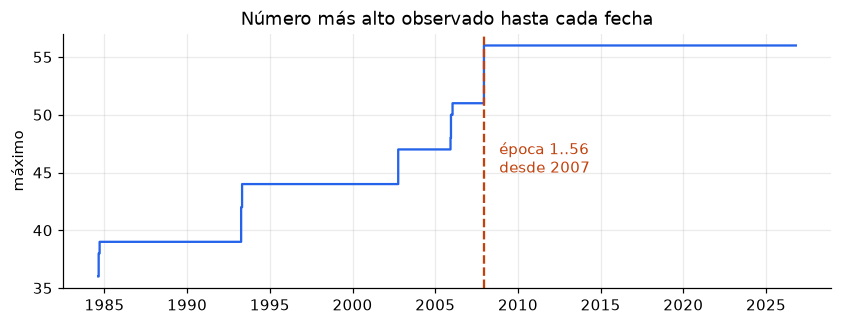

In [3]:
maximo_corrido = datos[COLS].max(axis=1).cummax()
nuevo_max = maximo_corrido.ne(maximo_corrido.shift())
cambios = datos.loc[nuevo_max, ["CONCURSO", "FECHA"]].assign(maximo=maximo_corrido[nuevo_max].to_numpy())
inicio = nu.inicio_era(datos)
era = datos[datos.CONCURSO >= inicio].reset_index(drop=True)
# Si el formato 1..56 hubiera empezado antes del concurso detectado, esos sorteos no habrían sacado
# ningún número de 52 a 56 (contando R7). La probabilidad de eso en un sorteo es C(51,7)/C(56,7).
p_sin_52_56 = math.comb(51, 7) / math.comb(56, 7)
print(cambios.to_string(index=False))
print(f"Época actual: desde el concurso {inicio} ({era.FECHA.iloc[0]:%d/%m/%Y}), {len(era)} sorteos")
print(f"P(un sorteo de 1..56 sin ningún 52-56) = {p_sin_52_56:.3f}; 10 seguidos = {p_sin_52_56 ** 10:.4f}")

fig, ax = plt.subplots(figsize=(9, 3))
ax.step(datos.FECHA, maximo_corrido, where="post", color=COLOR["dato"])
ax.axvline(era.FECHA.iloc[0], color=COLOR["dl"], ls="--")
ax.set(title="Número más alto observado hasta cada fecha", ylabel="máximo")
ax.annotate(f"época 1..56\ndesde {era.FECHA.iloc[0]:%Y}", (era.FECHA.iloc[0], 45), xytext=(10, 0),
            textcoords="offset points", color=COLOR["dl"])
guardar_figura(fig, "01_formato")

RESULTADOS["datos"] = {
    "fuente": fuente, "n_sorteos": int(len(datos)),
    "primer_concurso": int(datos.CONCURSO.iloc[0]), "primera_fecha": f"{datos.FECHA.iloc[0]:%Y-%m-%d}",
    "ultimo_concurso": int(datos.CONCURSO.iloc[-1]), "ultima_fecha": f"{datos.FECHA.iloc[-1]:%Y-%m-%d}",
    "validacion": validacion,
    "cambios_formato": [{"concurso": int(c), "fecha": f"{f:%Y-%m-%d}", "maximo": int(m)}
                        for c, f, m in cambios.itertuples(index=False)],
    "era_inicio_concurso": inicio, "era_inicio_fecha": f"{era.FECHA.iloc[0]:%Y-%m-%d}",
    "era_n": int(len(era)), "p_sorteo_sin_52_56": p_sin_52_56,
    "ultimos": era[["CONCURSO"] + COLS].tail(8).astype(int).to_dict("records"),
    "ultimas_fechas": [f"{f:%Y-%m-%d}" for f in era.FECHA.tail(8)],
}

## 3. La distribución de R1, y por qué la respuesta "ingenua" es la mediana
Si las 6 bolas salen al azar de 56, la probabilidad de que la más chica valga $k$ es

$$P(R1 = k) = \frac{\binom{56-k}{5}}{\binom{56}{6}}, \qquad k = 1,\dots,51$$

(una bola vale $k$ y las otras cinco salen de las $56-k$ mayores). Como el examen castiga el **error
absoluto**, la predicción constante con mayor calificación esperada es la **mediana**, no el promedio.

Mediana teórica 6, media teórica 8.14; observadas: mediana 6, media 8.10
Mejor predicción constante: 6 -> calificación esperada 8.503
Chi-cuadrada R1 vs teoría: 24.2 con 29 gl, p = 0.719


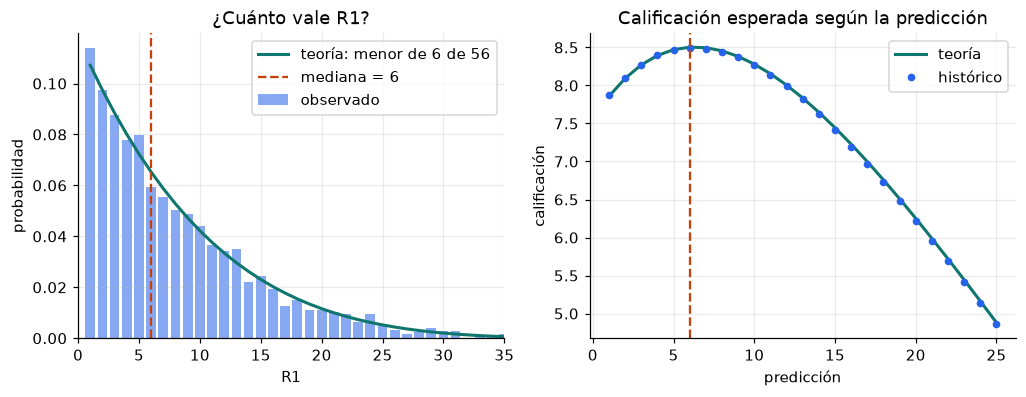

In [4]:
valores = np.arange(1, R1_MAX + 1)
pmf_teorica = nu.pmf_teorica()
r1 = era.R1.to_numpy()
pmf_empirica = np.bincount(r1, minlength=R1_MAX + 1)[1:] / len(r1)
mediana_teorica = int(valores[np.searchsorted(np.cumsum(pmf_teorica), 0.5)])
media_teorica = float((valores * pmf_teorica).sum())


def calif_esperada(pred, pmf=pmf_teorica):
    return float((calificacion(valores, pred) * pmf).sum())


curva = [{"prediccion": int(p), "teorica": calif_esperada(p), "empirica": float(calificacion(r1, p).mean())}
         for p in range(1, 26)]
mejor_constante = max(curva, key=lambda c: c["teorica"])["prediccion"]

# Bondad de ajuste a la fórmula: desde el primer valor que espera menos de 5 casos, la cola va en una sola celda
esperado, observado = pmf_teorica * len(r1), pmf_empirica * len(r1)
cola = int(np.argmax(esperado < 5))
chi_r1 = stats.chisquare(np.append(observado[:cola], observado[cola:].sum()),
                         np.append(esperado[:cola], esperado[cola:].sum()))

print(f"Mediana teórica {mediana_teorica}, media teórica {media_teorica:.2f}; "
      f"observadas: mediana {np.median(r1):.0f}, media {r1.mean():.2f}")
print(f"Mejor predicción constante: {mejor_constante} -> calificación esperada {calif_esperada(mejor_constante):.3f}")
print(f"Chi-cuadrada R1 vs teoría: {chi_r1.statistic:.1f} con {cola} gl, p = {chi_r1.pvalue:.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6))
a1.bar(valores, pmf_empirica, color=COLOR["dato"], alpha=0.55, label="observado")
a1.plot(valores, pmf_teorica, color=COLOR["teoria"], lw=2, label="teoría: menor de 6 de 56")
a1.axvline(mediana_teorica, color=COLOR["dl"], ls="--", label=f"mediana = {mediana_teorica}")
a1.set(xlim=(0, 35), title="¿Cuánto vale R1?", xlabel="R1", ylabel="probabilidad")
a1.legend()
pr = [c["prediccion"] for c in curva]
a2.plot(pr, [c["teorica"] for c in curva], color=COLOR["teoria"], lw=2, label="teoría")
a2.plot(pr, [c["empirica"] for c in curva], "o", color=COLOR["dato"], ms=4, label="histórico")
a2.axvline(mejor_constante, color=COLOR["dl"], ls="--")
a2.set(title="Calificación esperada según la predicción", xlabel="predicción", ylabel="calificación")
a2.legend()
guardar_figura(fig, "02_distribucion_r1")

RESULTADOS["distribucion"] = {
    "pmf_teorica": pmf_teorica.tolist(), "pmf_empirica": pmf_empirica.tolist(),
    "mediana_teorica": mediana_teorica, "media_teorica": media_teorica,
    "mediana_observada": float(np.median(r1)), "media_observada": float(r1.mean()),
    "p_r1_hasta_10": float(pmf_teorica[:10].sum()), "p_r1_hasta_mediana": float(pmf_teorica[:mediana_teorica].sum()),
    "curva_calificacion": curva, "mejor_constante": mejor_constante,
    "calif_mejor_constante": calif_esperada(mejor_constante),
    "chi2_r1": {"estadistico": float(chi_r1.statistic), "gl": cola, "p": float(chi_r1.pvalue)},
}

## 4. ¿El sorteo tiene memoria? Pruebas estadísticas
Un modelo solo puede ganarle a la mediana si el pasado dice algo del futuro. Se prueban cuatro cosas:
1. **Frecuencias**: ¿todas las bolas salen igual de seguido? (chi-cuadrada)
2. **Autocorrelación** de R1 a 1-20 sorteos de distancia y prueba de **Ljung-Box**.
3. **Prueba de rachas**: ¿R1 alterna entre "bajo" y "alto" como lo haría el azar?
4. **Independencia**: ¿el R1 anterior cambia la distribución del siguiente? (tabla de contingencia)

Frecuencia por bola: mín 209, máx 262, esperado 235.0; chi2 = 47.6, p = 0.749
Autocorrelaciones fuera de ±0.042: 0 de 20 (por azar se espera 1)
Ljung-Box: p(10) = 0.773, p(20) = 0.978
Rachas: 1081 observadas vs 1096.4 esperadas, z = -0.66, p = 0.512
Independencia R1 anterior vs siguiente: chi2 = 5.7, p = 0.771
R1 siguiente   1-3   4-6  7-10   11+
R1 anterior                         
1-3           32.2  22.1  18.3  27.4
4-6           27.5  22.1  21.0  29.4
7-10          29.8  20.2  19.3  30.7
11+           29.5  22.1  21.0  27.4


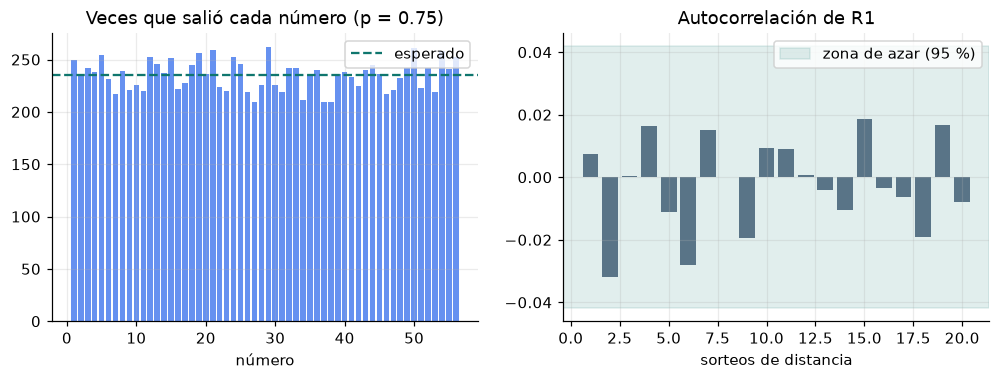

In [5]:
frec = np.bincount(era[COLS[:6]].to_numpy().ravel(), minlength=N_BOLAS + 1)[1:]
chi_bolas = stats.chisquare(frec)

n = len(r1)
centrado = r1 - r1.mean()
acf = np.array([np.sum(centrado[l:] * centrado[:-l]) / np.sum(centrado ** 2) for l in range(1, 21)])
banda = 1.96 / math.sqrt(n)
ljung_p = {L: float(stats.chi2.sf(n * (n + 2) * np.sum(acf[:L] ** 2 / (n - np.arange(1, L + 1))), L))
           for L in (10, 20)}

alto = r1 > mediana_teorica
rachas = 1 + int(np.sum(alto[1:] != alto[:-1]))
n1, n2 = int(alto.sum()), int((~alto).sum())
mu = 2 * n1 * n2 / (n1 + n2) + 1
var = 2 * n1 * n2 * (2 * n1 * n2 - n1 - n2) / ((n1 + n2) ** 2 * (n1 + n2 - 1))
z_rachas = (rachas - mu) / math.sqrt(var)
p_rachas = float(2 * stats.norm.sf(abs(z_rachas)))

grupos = pd.cut(r1, [0, 3, 6, 10, 51], labels=["1-3", "4-6", "7-10", "11+"])
tabla = pd.crosstab(pd.Series(grupos[:-1], name="R1 anterior"), pd.Series(grupos[1:], name="R1 siguiente"))
chi_ind = stats.chi2_contingency(tabla)

print(f"Frecuencia por bola: mín {frec.min()}, máx {frec.max()}, esperado {frec.mean():.1f}; "
      f"chi2 = {chi_bolas.statistic:.1f}, p = {chi_bolas.pvalue:.3f}")
print(f"Autocorrelaciones fuera de ±{banda:.3f}: {int(np.sum(np.abs(acf) > banda))} de 20 (por azar se espera 1)")
print(f"Ljung-Box: p(10) = {ljung_p[10]:.3f}, p(20) = {ljung_p[20]:.3f}")
print(f"Rachas: {rachas} observadas vs {mu:.1f} esperadas, z = {z_rachas:.2f}, p = {p_rachas:.3f}")
print(f"Independencia R1 anterior vs siguiente: chi2 = {chi_ind.statistic:.1f}, p = {chi_ind.pvalue:.3f}")
print((tabla.div(tabla.sum(axis=1), axis=0) * 100).round(1))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
a1.bar(np.arange(1, N_BOLAS + 1), frec, color=COLOR["dato"], alpha=0.7)
a1.axhline(frec.mean(), color=COLOR["teoria"], ls="--", label="esperado")
a1.set(title=f"Veces que salió cada número (p = {chi_bolas.pvalue:.2f})", xlabel="número")
a1.legend()
a2.bar(range(1, 21), acf, color=[COLOR["malo"] if abs(a) > banda else COLOR["base"] for a in acf])
a2.axhspan(-banda, banda, color=COLOR["teoria"], alpha=0.12, label="zona de azar (95 %)")
a2.set(title="Autocorrelación de R1", xlabel="sorteos de distancia")
a2.legend()
guardar_figura(fig, "03_memoria")

RESULTADOS["pruebas"] = {
    "frecuencias": frec.tolist(), "esperado_por_bola": float(frec.mean()),
    "chi2_bolas": {"estadistico": float(chi_bolas.statistic), "gl": N_BOLAS - 1, "p": float(chi_bolas.pvalue)},
    "acf": acf.tolist(), "banda": banda, "acf_fuera": int(np.sum(np.abs(acf) > banda)),
    "ljung_box_p": {str(k): v for k, v in ljung_p.items()},
    "rachas": {"observadas": rachas, "esperadas": mu, "z": z_rachas, "p": p_rachas},
    "independencia": {"estadistico": float(chi_ind.statistic), "gl": int(chi_ind.dof), "p": float(chi_ind.pvalue),
                      "filas": list(tabla.index.astype(str)),
                      "pct": (tabla.div(tabla.sum(axis=1), axis=0) * 100).round(1).to_numpy().tolist()},
}

## 5. Los modelos de Deep Learning
Cada red ve los últimos $k$ sorteos completos y predice R1 del siguiente. Lo que se varió en la búsqueda:

| Dimensión | Opciones |
|---|---|
| Familia | **MLP**, **LSTM**, **GRU**, **CNN** 1D con dilatación, **Transformer** (encoder con atención) |
| Salida y pérdida | regresión con **L1** (error absoluto), regresión con **MSE**, **clasificación** en 51 clases (entropía cruzada) y se predice la mediana de la distribución |
| Ventana $k$ | 5, 10, 20, 50 sorteos previos |
| Entrada por sorteo | R1..R6 escalados (6), *multi-hot* de las 56 bolas (56), o ambas (62) |
| Hiperparámetros | ancho 16-128, 1-2 capas, dropout 0-0.4, tasa de aprendizaje, weight decay |

La pérdida importa: **L1 aprende la mediana condicional**, que es lo que premia el examen; **MSE aprende
la media**. Entrenamiento: Adam, early stopping sobre el último 15 % del entrenamiento (en orden temporal,
nunca al azar) y varias semillas promediadas.

Antes de la búsqueda, un ejemplo: una MLP con L1 entrenada aquí mismo.

Épocas: 25; salida de la red en validación: mín 5.36, máx 8.46, desviación 0.514


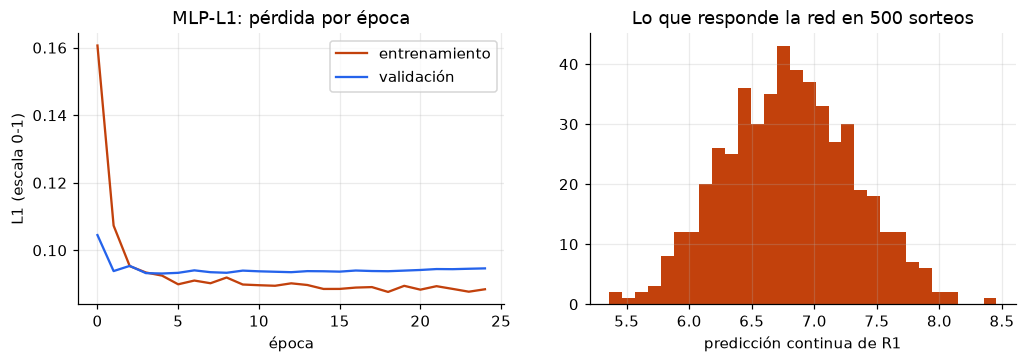

In [6]:
val_idx, prueba_idx = nu.particion(era)
cfg_demo = dict(familia="MLP", perdida="l1", ventana=10, entrada="escalada", oculto=64, capas=2,
                dropout=0.2, lr=1e-3, weight_decay=1e-4)
m_demo = nu.matriz_entrada(era, "escalada")
entreno = np.arange(nu.VENTANA_MAX, val_idx[0])
f_demo, hist_demo = nu.entrenar(cfg_demo, nu.ventanas(m_demo, entreno, 10), r1[entreno], 0, historial=True)
salida_demo = f_demo(nu.ventanas(m_demo, val_idx, 10))
print(f"Épocas: {len(hist_demo)}; salida de la red en validación: mín {salida_demo.min():.2f}, "
      f"máx {salida_demo.max():.2f}, desviación {salida_demo.std():.3f}")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.2))
a1.plot([h[0] for h in hist_demo], color=COLOR["dl"], label="entrenamiento")
a1.plot([h[1] for h in hist_demo], color=COLOR["dato"], label="validación")
a1.set(title="MLP-L1: pérdida por época", xlabel="época", ylabel="L1 (escala 0-1)")
a1.legend()
a2.hist(salida_demo, bins=30, color=COLOR["dl"])
a2.set(title="Lo que responde la red en 500 sorteos", xlabel="predicción continua de R1")
guardar_figura(fig, "04_entrenamiento")
RESULTADOS["demo"] = {"curva": hist_demo, "n": int(len(val_idx)),"salida_min": float(salida_demo.min()),
                      "salida_max": float(salida_demo.max()), "salida_std": float(salida_demo.std()),
                      "salida_hist": np.histogram(salida_demo, bins=20)[0].tolist(),
                      "salida_bordes": np.histogram(salida_demo, bins=20)[1].tolist()}

## 6. La búsqueda: muchas configuraciones compitiendo en validación
`experimentos.py` probó cada configuración "hacia adelante" en los sorteos de **validación**: para
predecir el sorteo $t$ la red solo conoció los sorteos anteriores a $t$.

**El protocolo, fijado antes de ver resultados:**
1. Se elige el **campeón** usando solo validación (la mejor configuración, o el ensamble de las 5 mejores
   si le gana en validación).
2. El campeón se evalúa **una sola vez** en los últimos 500 sorteos (**prueba**), que no participaron
   en ninguna decisión.
3. Se envía la predicción del campeón **solo si le gana a la constante teórica en prueba** con un intervalo
   de confianza de 95 % (bootstrap pareado) completamente por encima de cero. Si no, se envía la constante.

240 configuraciones; validación 2019-05-15 a 2023-08-09
Constante 6 en validación: 8.448
Configuraciones que le ganan a la constante en validación: 42 de 240; mejor 8.459, peor 8.354
             count    max  median
familia                          
CNN             43  8.454   8.445
GRU             49  8.459   8.442
LSTM            48  8.453   8.448
MLP             60  8.456   8.437
Transformer     40  8.451   8.442
         count    max  median
perdida                      
clase      124  8.459   8.448
l1         111  8.453   8.436
mse          5  8.393   8.375
                                                  nombre  calificacion
    GRU-CLASE k=50 ambas h=16x2 do=0.4 lr=0.001 wd=0.001        8.4592
     GRU-CLASE k=5 ambas h=32x2 do=0.4 lr=0.001 wd=0.001        8.4556
    MLP-CLASE k=5 escalada h=32x2 do=0.0 lr=0.001 wd=0.0        8.4556
  CNN-CLASE k=20 escalada h=128x2 do=0.4 lr=0.001 wd=0.0        8.4544
    CNN-CLASE k=5 ambas h=64x2 do=0.2 lr=0.003 wd=0.0001        8.4538
MLP

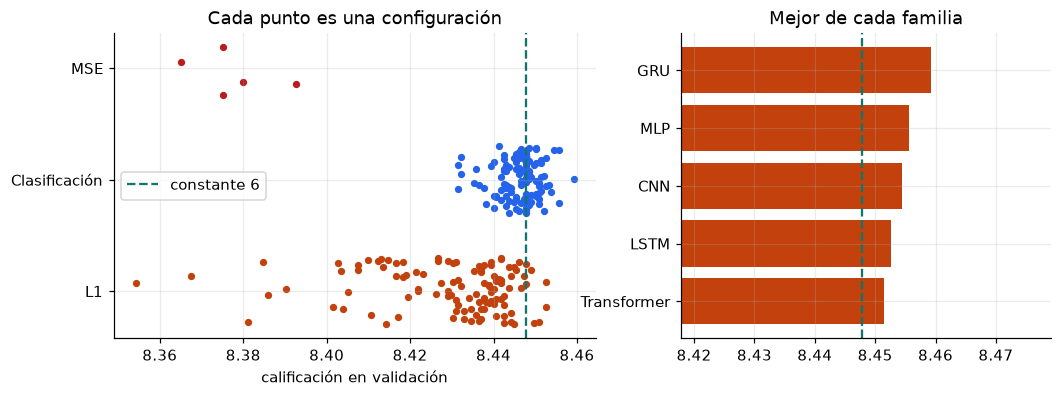

In [7]:
busqueda = [json.loads(l) for l in (nu.SALIDA / "busqueda.jsonl").read_text(encoding="utf-8").splitlines() if l.strip()]
fin = json.loads((nu.SALIDA / "finalistas.json").read_text(encoding="utf-8"))
busq = pd.DataFrame(busqueda).sort_values("calificacion", ascending=False)
y_val = np.array(fin["validacion"]["y"])
constante = fin["constante"]
ref_val = float(calificacion(y_val, constante).mean())
print(f"{len(busq)} configuraciones; validación {fin['validacion']['desde']} a {fin['validacion']['hasta']}")
print(f"Constante {constante} en validación: {ref_val:.3f}")
print(f"Configuraciones que le ganan a la constante en validación: {(busq.calificacion > ref_val).sum()} "
      f"de {len(busq)}; mejor {busq.calificacion.max():.3f}, peor {busq.calificacion.min():.3f}")
print(busq.groupby("familia").calificacion.agg(["count", "max", "median"]).round(3))
print(busq.groupby("perdida").calificacion.agg(["count", "max", "median"]).round(3))
print(busq.head(10)[["nombre", "calificacion"]].to_string(index=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
for i, (perd, col) in enumerate([("l1", COLOR["dl"]), ("clase", COLOR["dato"]), ("mse", COLOR["malo"])]):
    sub = busq[busq.perdida == perd]
    a1.scatter(sub.calificacion, np.random.default_rng(i).uniform(-0.3, 0.3, len(sub)) + i, s=14, color=col)
a1.axvline(ref_val, color=COLOR["teoria"], ls="--", label=f"constante {constante}")
a1.set(yticks=[0, 1, 2], yticklabels=["L1", "Clasificación", "MSE"], xlabel="calificación en validación",
       title="Cada punto es una configuración")
a1.legend()
fam = busq.groupby("familia").calificacion.max().sort_values()
a2.barh(fam.index, fam.to_numpy(), color=COLOR["dl"])
a2.axvline(ref_val, color=COLOR["teoria"], ls="--")
a2.set(xlim=(min(fam.min(), ref_val) - 0.03, max(fam.max(), ref_val) + 0.02), title="Mejor de cada familia")
guardar_figura(fig, "05_busqueda")

## 7. La prueba final: el campeón contra sorteos que nunca vio

Prueba: 2023-08-11 a 2026-10-18 (500 sorteos)
                                           tipo  validacion  calificacion  dif_vs_ref  ic_bajo  ic_alto  moda  pct_moda
metodo                                                                                                                 
MLP-Clasif. k=5 (#187)            Deep Learning       8.456         8.526       0.002   -0.011    0.016     6     0.728
Constante 6 (teoría)                Estadístico       8.448         8.523       0.000    0.000    0.000     6     1.000
Mediana histórica                   Estadístico       8.448         8.523       0.000    0.000    0.000     6     1.000
CNN-Clasif. k=20 (#133)           Deep Learning       8.454         8.522      -0.002   -0.010    0.006     6     0.910
Números calientes (Dirichlet)       Estadístico       8.438         8.522      -0.002   -0.007    0.004     6     0.954
Ensamble top-5 (mediana)          Deep Learning       8.459         8.519      -0.005   -0.012    0.002     6     

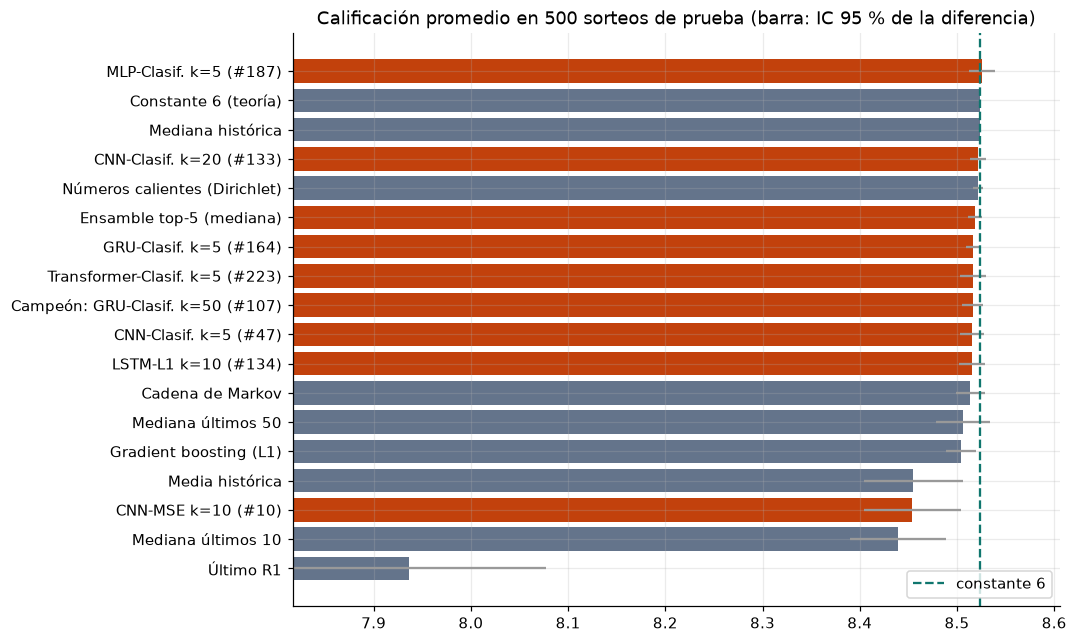

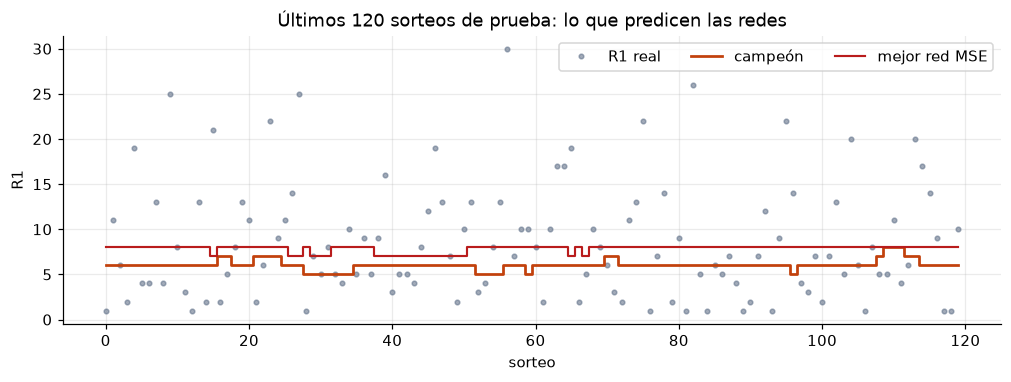

Corrida anterior (160 configuraciones): Campeón: Ensamble top-5 (mediana) -0.007 vs constante; la prueba final se usó una vez por corrida


In [8]:
y_pru = np.array(fin["prueba"]["y"])
calif_ref = calificacion(y_pru, constante)
rng = np.random.default_rng(0)
muestras = rng.integers(0, len(y_pru), size=(N_BOOTSTRAP, len(y_pru)))
finalistas = fin["finalistas"]


def nombre_corto(cfg):
    return f"{cfg['familia']}-{cfg['perdida'].upper().replace('CLASE', 'Clasif.')} k={cfg['ventana']}"


metodos = {}
for i, cfg in finalistas.items():
    metodos[(f"Campeón: " if str(fin["campeon"]) == i else "") + nombre_corto(cfg) + f" (#{i})"] = \
        ("Deep Learning", fin["prueba"]["redes"][i], cfg["calificacion"], i)
metodos[("Campeón: " if fin["campeon"] == "ensamble" else "") + "Ensamble top-5 (mediana)"] = \
    ("Deep Learning", fin["prueba"]["ensamble"], fin["validacion"]["ensamble_calificacion"], "ensamble")
for k, v in fin["prueba"]["estadisticos"].items():
    metodos[k] = ("Estadístico", v, float(calificacion(y_val, fin["validacion"]["estadisticos"][k]).mean()), None)
metodos["Gradient boosting (L1)"] = ("ML clásico", fin["prueba"]["gbm"],
                                     float(calificacion(y_val, fin["validacion"]["gbm"]).mean()), None)

tabla_res = []
for nombre, (tipo, p, cal_val, clave) in metodos.items():
    p = np.asarray(p)
    c = calificacion(y_pru, p)
    boot = (c - calif_ref)[muestras].mean(axis=1)
    moda = int(pd.Series(p).mode().iloc[0])
    tabla_res.append({"metodo": nombre, "tipo": tipo, "clave": clave, "validacion": cal_val,
                      "calificacion": float(c.mean()), "error_abs": float(np.abs(y_pru - p).mean()),
                      "dif_vs_ref": float((c - calif_ref).mean()),
                      "ic_bajo": float(np.percentile(boot, 2.5)), "ic_alto": float(np.percentile(boot, 97.5)),
                      "moda": moda, "pct_moda": float((p == moda).mean()), "rango": [int(p.min()), int(p.max())]})
tabla_res.sort(key=lambda r: -r["calificacion"])
campeon = next(r for r in tabla_res if r["metodo"].startswith("Campeón"))
gana = campeon["ic_bajo"] > 0
print(f"Prueba: {fin['prueba']['desde']} a {fin['prueba']['hasta']} ({len(y_pru)} sorteos)")
print(pd.DataFrame(tabla_res).set_index("metodo")[["tipo", "validacion", "calificacion", "dif_vs_ref", "ic_bajo",
                                                    "ic_alto", "moda", "pct_moda"]].round(3).to_string())
print(f"\n{campeon['metodo']}: validación {campeon['validacion']:.3f} -> prueba {campeon['calificacion']:.3f};"
      f" diferencia vs constante {campeon['dif_vs_ref']:+.3f} (IC 95 % {campeon['ic_bajo']:+.3f} a {campeon['ic_alto']:+.3f})")
print("¿Le gana a la constante de forma significativa?", "SÍ" if gana else "NO")

fig, ax = plt.subplots(figsize=(9, 0.32 * len(tabla_res) + 1))
orden = list(reversed(tabla_res))
ax.barh([r["metodo"] for r in orden], [r["calificacion"] for r in orden],
        xerr=np.array([[r["dif_vs_ref"] - r["ic_bajo"], r["ic_alto"] - r["dif_vs_ref"]] for r in orden]).T,
        color=[COLOR["dl"] if r["tipo"] == "Deep Learning" else COLOR["base"] for r in orden], ecolor="#999")
ax.axvline(float(calif_ref.mean()), color=COLOR["teoria"], ls="--", label=f"constante {constante}")
ax.set(xlim=(min(r["calificacion"] for r in tabla_res) - 0.12, max(r["calificacion"] for r in tabla_res) + 0.08),
       title=f"Calificación promedio en {len(y_pru)} sorteos de prueba (barra: IC 95 % de la diferencia)")
ax.legend(loc="lower right")
guardar_figura(fig, "06_prueba")

ult = 120
serie = {"real": y_pru[-ult:].tolist()}
mse_id = str(fin["mejor_mse"])
clave_campeon = campeon["clave"]
serie["Campeón"] = (fin["prueba"]["ensamble"] if clave_campeon == "ensamble" else fin["prueba"]["redes"][clave_campeon])[-ult:]
serie["Mejor MSE"] = fin["prueba"]["redes"][mse_id][-ult:]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(range(ult), serie["real"], "o", ms=3, color=COLOR["base"], alpha=0.6, label="R1 real")
ax.step(range(ult), serie["Campeón"], where="mid", color=COLOR["dl"], lw=1.8, label="campeón")
ax.step(range(ult), serie["Mejor MSE"], where="mid", color=COLOR["malo"], lw=1.4, label="mejor red MSE")
ax.set(title=f"Últimos {ult} sorteos de prueba: lo que predicen las redes", xlabel="sorteo", ylabel="R1")
ax.legend(ncol=3)
guardar_figura(fig, "07_predicciones")

RESULTADOS["busqueda"] = {
    "n_configs": int(len(busq)), "n_validacion": int(len(y_val)), "constante": constante, "ref_validacion": ref_val,
    "validacion_desde": fin["validacion"]["desde"], "validacion_hasta": fin["validacion"]["hasta"],
    "le_ganan_en_validacion": int((busq.calificacion > ref_val).sum()),
    "mejor": float(busq.calificacion.max()), "peor": float(busq.calificacion.min()),
    "puntos": busq[["familia", "perdida", "ventana", "entrada", "calificacion"]].to_dict("records"),
    "por_familia": busq.groupby("familia").calificacion.agg(["count", "max", "median"]).round(4).reset_index().to_dict("records"),
    "por_perdida": busq.groupby("perdida").calificacion.agg(["count", "max", "median"]).round(4).reset_index().to_dict("records"),
    "top10": busq.head(10)[["id", "nombre", "calificacion"]].to_dict("records"),
    "config": fin["config"],
}
RESULTADOS["prueba"] = {"desde": fin["prueba"]["desde"], "hasta": fin["prueba"]["hasta"], "n": int(len(y_pru)),
                        "tabla": tabla_res, "campeon": campeon, "gana": bool(gana), "serie": serie}

# La búsqueda se amplió después de una primera corrida con menos configuraciones. Cada corrida eligió su campeón
# solo con validación, pero la prueba final se usó una vez por corrida: se declara aquí en vez de esconderlo.
anterior = nu.SALIDA / "resultados_160.json"
if anterior.exists():
    a = json.loads(anterior.read_text(encoding="utf-8"))
    RESULTADOS["prueba"]["corrida_anterior"] = {
        "n_configs": a["busqueda"]["n_configs"], "campeon": a["prueba"]["campeon"]["metodo"],
        "dif_vs_ref": a["prueba"]["campeon"]["dif_vs_ref"], "ic_bajo": a["prueba"]["campeon"]["ic_bajo"],
        "ic_alto": a["prueba"]["campeon"]["ic_alto"], "gana": a["prueba"]["gana"]}
    print(f"Corrida anterior ({a['busqueda']['n_configs']} configuraciones): {a['prueba']['campeon']['metodo']} "
          f"{a['prueba']['campeon']['dif_vs_ref']:+.3f} vs constante; la prueba final se usó una vez por corrida")

## 8. Por dentro de las redes, y ¿se sobreentrenaron?
Para cada finalista se reconstruye su arquitectura (capas, neuronas y parámetros, contados por PyTorch) y se
entrena una vez con los sorteos anteriores a la validación, guardando el error de cada época:
- **error en entrenamiento**: sobre los sorteos con los que aprende;
- **error en sorteos no vistos**: sobre el 15 % más reciente, que la red no usa para aprender.

Una red **sobreentrenada** (memorizó en vez de aprender) muestra el primer error bajando mientras el segundo
sube, y califica mucho mejor en los sorteos que ya vio que en los nuevos. El *early stopping* detiene el
entrenamiento en la época con menor error en sorteos no vistos. Para que se vea la diferencia, al final se
entrena a propósito una red grande **sin** ese freno.

Siempre 6: 8.510 en los sorteos de entrenamiento, 8.451 en los no vistos


GRU-Clasif. k=50               6,339 parámetros  épocas  90 (mejor  70)  ventaja sobre la constante: entrenamiento +0.022 / no vistos +0.004  (83 s)


GRU-Clasif. k=5               17,235 parámetros  épocas  49 (mejor  29)  ventaja sobre la constante: entrenamiento +0.008 / no vistos -0.002  (9 s)


MLP-Clasif. k=5                3,731 parámetros  épocas  55 (mejor  35)  ventaja sobre la constante: entrenamiento -0.006 / no vistos +0.005  (2 s)


CNN-Clasif. k=20              58,291 parámetros  épocas  43 (mejor  23)  ventaja sobre la constante: entrenamiento +0.001 / no vistos +0.003  (17 s)


CNN-Clasif. k=5               27,635 parámetros  épocas  25 (mejor   5)  ventaja sobre la constante: entrenamiento +0.018 / no vistos -0.001  (3 s)


LSTM-L1 k=10                 227,457 parámetros  épocas  21 (mejor   1)  ventaja sobre la constante: entrenamiento -0.007 / no vistos -0.009  (11 s)


Transformer-Clasif. k=5      279,475 parámetros  épocas  24 (mejor   4)  ventaja sobre la constante: entrenamiento +0.002 / no vistos -0.032  (17 s)


CNN-MSE k=10                   3,745 parámetros  épocas  59 (mejor  39)  ventaja sobre la constante: entrenamiento -0.062 / no vistos -0.053  (6 s)



Sin early stopping (859,905 parámetros): error en entrenamiento 10.38 -> 0.27 números; en no vistos mejor 5.38 (época 5) -> 5.67 al final


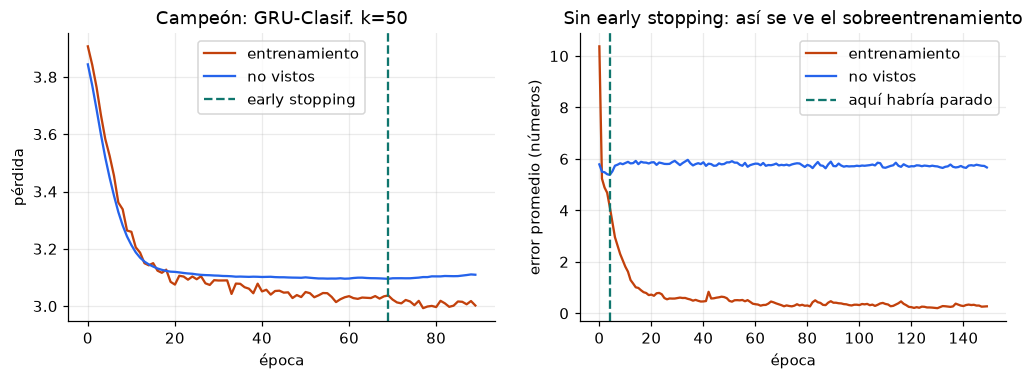

In [9]:
import torch

ENTRADA_TXT = {"escalada": "R1..R6 de cada sorteo", "multihot": "qué bolas salieron (56 casillas)",
               "ambas": "R1..R6 y qué bolas salieron"}


def arquitectura(cfg):
    """Capas legibles de una configuración, con sus neuronas y parámetros contados del modelo real."""
    d = nu.matriz_entrada(era, cfg["entrada"]).shape[1]
    k, fam, clase = cfg["ventana"], cfg["familia"], cfg["perdida"] == "clase"
    red = nu.FAMILIAS[fam](k, d, R1_MAX if clase else 1, oculto=cfg["oculto"], dropout=cfg["dropout"], capas=cfg["capas"])
    n = lambda mod: int(sum(p.numel() for p in mod.parameters()))
    lineales = [m for m in red.modules() if isinstance(m, torch.nn.Linear)]
    capas = [{"tipo": "entrada", "nombre": "Entrada", "unidades": d, "params": 0,
              "detalle": f"los últimos {k} sorteos; de cada uno, {d} valores ({ENTRADA_TXT[cfg['entrada']]})"}]
    if fam == "MLP":
        capas[0].update(unidades=k * d, detalle=f"{k} sorteos × {d} valores = {k * d} números en una fila "
                                                 f"({ENTRADA_TXT[cfg['entrada']]})")
        for i, m in enumerate(lineales[:-1]):
            capas.append({"tipo": "densa", "nombre": f"Capa densa {i + 1}", "unidades": m.out_features, "params": n(m),
                          "detalle": f"{m.out_features} neuronas conectadas con todo lo anterior"})
    elif fam in ("LSTM", "GRU"):
        for l in range(cfg["capas"]):
            capas.append({"tipo": "recurrente", "nombre": f"{fam}, capa {l + 1}", "unidades": cfg["oculto"],
                          "params": int(sum(p.numel() for nm, p in red.rnn.named_parameters() if nm.endswith(f"_l{l}"))),
                          "detalle": f"{cfg['oculto']} neuronas con memoria; leen los {k} sorteos uno tras otro"})
    elif fam == "CNN":
        for i, m in enumerate(c for c in red.modules() if isinstance(c, torch.nn.Conv1d)):
            capas.append({"tipo": "conv", "nombre": f"Convolución {i + 1}", "unidades": m.out_channels, "params": n(m),
                          "detalle": f"{m.out_channels} filtros que miran 3 sorteos a la vez (de {m.dilation[0]} en {m.dilation[0]})"})
        capas.append({"tipo": "resumen", "nombre": "Promedio", "unidades": cfg["oculto"], "params": 0,
                      "detalle": "resume toda la ventana en un solo vector"})
    else:
        capas.append({"tipo": "proyeccion", "nombre": "Proyección", "unidades": cfg["oculto"],
                      "params": n(red.entrada) + red.posicion.numel(),
                      "detalle": f"convierte cada sorteo en {cfg['oculto']} números y le suma su posición"})
        for i, capa in enumerate(red.encoder.layers):
            capas.append({"tipo": "atencion", "nombre": f"Atención {i + 1}", "unidades": cfg["oculto"], "params": n(capa),
                          "detalle": f"4 cabezas de atención (cada sorteo consulta a los demás) + {2 * cfg['oculto']} neuronas"})
    capas.append({"tipo": "salida", "nombre": "Salida", "unidades": lineales[-1].out_features, "params": n(lineales[-1]),
                  "detalle": "51 probabilidades, una por cada valor posible de R1; se predice la mediana" if clase
                  else "un solo número: el R1 estimado"})
    assert n(red) == sum(c["params"] for c in capas), (fam, n(red), sum(c["params"] for c in capas))
    return capas, n(red)


redes = []
entreno = np.arange(nu.VENTANA_MAX, val_idx[0])
# Los dos periodos no califican igual ni para la constante (2007-2019 contra 2019-2023), así que el
# sobreentrenamiento se mide como VENTAJA sobre "siempre 6" dentro de cada periodo, no como calificación cruda.
const_ent = float(calificacion(r1[entreno], constante).mean())
const_val = float(calificacion(r1[val_idx], constante).mean())
print(f"Siempre {constante}: {const_ent:.3f} en los sorteos de entrenamiento, {const_val:.3f} en los no vistos")
for i, cfg in finalistas.items():
    capas, total = arquitectura(cfg)
    m = nu.matriz_entrada(era, cfg["entrada"])
    X, Xv = nu.ventanas(m, entreno, cfg["ventana"]), nu.ventanas(m, val_idx, cfg["ventana"])
    t0 = time.time()
    f, hist = nu.entrenar(cfg, X, r1[entreno], 0, historial=True)
    cal_ent = float(calificacion(r1[entreno], nu.a_entero(cfg, [f(X)])).mean())
    cal_val = float(calificacion(r1[val_idx], nu.a_entero(cfg, [f(Xv)])).mean())
    redes.append({"id": i, "nombre": nombre_corto(cfg), "campeon": str(fin["campeon"]) == i,
                  **{k: cfg[k] for k in ["familia", "perdida", "ventana", "entrada", "oculto", "capas", "dropout",
                                         "lr", "weight_decay"]},
                  "capas_red": capas, "parametros": total, "curva": hist,
                  "mejor_epoca": int(np.argmin([h[1] for h in hist])) + 1, "epocas": len(hist),
                  "cal_entreno": cal_ent, "cal_no_vistos": cal_val, "n_entreno": int(len(entreno)),
                  "ventaja_entreno": cal_ent - const_ent, "ventaja_no_vistos": cal_val - const_val})
    print(f"{nombre_corto(cfg):<26} {total:>9,} parámetros  épocas {len(hist):>3} (mejor {redes[-1]['mejor_epoca']:>3})"
          f"  ventaja sobre la constante: entrenamiento {cal_ent - const_ent:+.3f} / no vistos {cal_val - const_val:+.3f}"
          f"  ({time.time() - t0:.0f} s)")
redes.sort(key=lambda r: (not r["campeon"], r["familia"]))

# Contraejemplo: una red grande, sin dropout y SIN early stopping, entrenada 150 épocas
cfg_sobre = dict(familia="MLP", perdida="l1", ventana=50, entrada="ambas", oculto=256, capas=2, dropout=0.0,
                 lr=1e-3, weight_decay=0.0)
m = nu.matriz_entrada(era, "ambas")
X, Xv = nu.ventanas(m, entreno, 50), nu.ventanas(m, val_idx, 50)
f_sobre, hist_sobre = nu.entrenar(cfg_sobre, X, r1[entreno], 0, epocas=150, paciencia=10 ** 9, historial=True)
# (entrenar devuelve los pesos de su mejor época; la curva sí registra las 150)
mejor_sobre = int(np.argmin([h[1] for h in hist_sobre])) + 1
sobre = {"capas_red": arquitectura(cfg_sobre)[0], "parametros": arquitectura(cfg_sobre)[1], "curva": hist_sobre,
         "mejor_epoca": mejor_sobre, "epocas": len(hist_sobre),
         # el error L1 está en escala 0-1 (R1/56): por 56 queda en "números de distancia"
         "error_entreno_inicio": hist_sobre[0][0] * N_BOLAS, "error_entreno_fin": hist_sobre[-1][0] * N_BOLAS,
         "error_val_mejor": hist_sobre[mejor_sobre - 1][1] * N_BOLAS, "error_val_fin": hist_sobre[-1][1] * N_BOLAS}
print(f"\nSin early stopping ({sobre['parametros']:,} parámetros): error en entrenamiento "
      f"{sobre['error_entreno_inicio']:.2f} -> {sobre['error_entreno_fin']:.2f} números; en no vistos "
      f"mejor {sobre['error_val_mejor']:.2f} (época {mejor_sobre}) -> {sobre['error_val_fin']:.2f} al final")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
camp_red = redes[0]
axs[0].plot([h[0] for h in camp_red["curva"]], color=COLOR["dl"], label="entrenamiento")
axs[0].plot([h[1] for h in camp_red["curva"]], color=COLOR["dato"], label="no vistos")
axs[0].axvline(camp_red["mejor_epoca"] - 1, color=COLOR["teoria"], ls="--", label="early stopping")
axs[0].set(title=f"Campeón: {camp_red['nombre']}", xlabel="época", ylabel="pérdida")
axs[0].legend()
axs[1].plot([h[0] * N_BOLAS for h in hist_sobre], color=COLOR["dl"], label="entrenamiento")
axs[1].plot([h[1] * N_BOLAS for h in hist_sobre], color=COLOR["dato"], label="no vistos")
axs[1].axvline(mejor_sobre - 1, color=COLOR["teoria"], ls="--", label="aquí habría parado")
axs[1].set(title="Sin early stopping: así se ve el sobreentrenamiento", xlabel="época", ylabel="error promedio (números)")
axs[1].legend()
guardar_figura(fig, "08_sobreentrenamiento")
RESULTADOS["redes"] = {"finalistas": redes, "sobreentrenada": sobre, "constante_entreno": const_ent,
                       "constante_no_vistos": const_val,
                       "max_ventaja_entreno": max(r["ventaja_entreno"] for r in redes if r["perdida"] != "mse")}

## 9. Tres sorteos con un solo número: cuánto pesa la suerte
La calificación final es el promedio de tres sorteos. Con la distribución teórica se calcula
**exactamente** la distribución de esa calificación (convolución de los tres errores).

Prediciendo 6: esperada 8.50; P(>= 9) = 35.8%, P(>= 8) = 78.1%, P(< 7) = 5.7%; 80 % de las veces entre 7.3 y 9.4


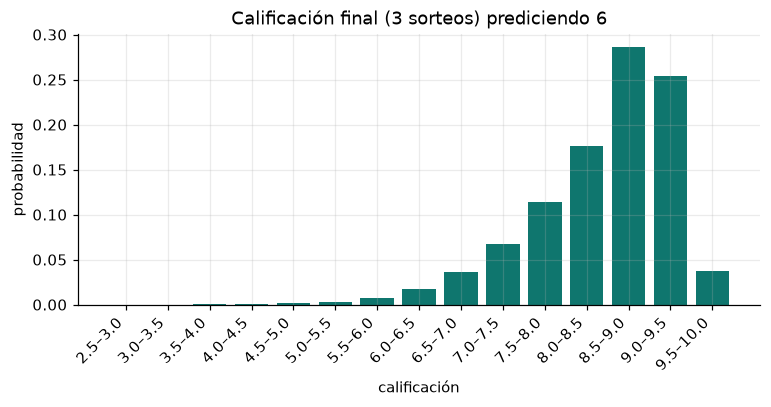

In [10]:
def distribucion_tres(pred):
    err = np.abs(valores - pred)
    p_err = np.bincount(err, weights=pmf_teorica)
    suma = np.convolve(np.convolve(p_err, p_err), p_err)
    return 10 - 0.3 * np.arange(len(suma)) / 3, suma


notas, prob = distribucion_tres(mejor_constante)
acum_desde_arriba = np.cumsum(prob)   # notas va de 10 hacia abajo
tres = {
    "prediccion": mejor_constante, "esperada": float((notas * prob).sum()),
    "p_9_o_mas": float(prob[notas >= 9 - 1e-9].sum()), "p_8_o_mas": float(prob[notas >= 8 - 1e-9].sum()),
    "p_menos_de_7": float(prob[notas < 7 - 1e-9].sum()),
    "p10": float(notas[np.searchsorted(acum_desde_arriba, 0.90)]),
    "p50": float(notas[np.searchsorted(acum_desde_arriba, 0.50)]),
    "p90": float(notas[np.searchsorted(acum_desde_arriba, 0.10)]),
    "histograma": [{"hasta": float(a), "prob": float(prob[(notas <= a + 1e-9) & (notas > a - 0.5 + 1e-9)].sum())}
                   for a in np.arange(10, 2.5, -0.5)],
    "por_prediccion": [{"prediccion": int(c), "esperada": float((distribucion_tres(c)[0] * distribucion_tres(c)[1]).sum())}
                       for c in range(2, 13)],
}
print(f"Prediciendo {mejor_constante}: esperada {tres['esperada']:.2f}; P(>= 9) = {tres['p_9_o_mas']:.1%}, "
      f"P(>= 8) = {tres['p_8_o_mas']:.1%}, P(< 7) = {tres['p_menos_de_7']:.1%}; "
      f"80 % de las veces entre {tres['p10']:.1f} y {tres['p90']:.1f}")

fig, ax = plt.subplots(figsize=(8, 3.2))
h = tres["histograma"][::-1]
ax.bar([f"{x['hasta'] - 0.5:.1f}–{x['hasta']:.1f}" for x in h], [x["prob"] for x in h], color=COLOR["teoria"])
ax.set(title=f"Calificación final (3 sorteos) prediciendo {mejor_constante}", xlabel="calificación", ylabel="probabilidad")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
guardar_figura(fig, "09_tres_sorteos")
RESULTADOS["tres_sorteos"] = tres

## 10. Predicción para el 23 de octubre
`experimentos.py` entrenó cada finalista con **toda** la época y le pidió el siguiente sorteo.
Se aplica la regla de decisión de la sección 6.

In [11]:
por_metodo = {nombre_corto(c) + f" (#{i})": fin["siguiente"][i]["prediccion"] for i, c in finalistas.items()}
por_metodo["Ensamble top-5 (mediana)"] = fin["siguiente_ensamble"]
por_metodo[f"Constante {constante} (teoría)"] = constante
por_metodo["Mediana histórica"] = int(np.median(r1))
pred_campeon = fin["siguiente_ensamble"] if fin["campeon"] == "ensamble" else fin["siguiente"][str(fin["campeon"])]["prediccion"]
if gana:
    prediccion_final, metodo_final = pred_campeon, campeon["metodo"]
    razon = "el campeón le ganó a la constante en la prueba final con un intervalo de confianza por encima de cero"
else:
    prediccion_final, metodo_final = constante, f"Constante {constante} (mediana teórica)"
    razon = "el campeón de Deep Learning no le ganó a la constante en la prueba final"
coinciden = sorted(k for k, v in por_metodo.items() if v == prediccion_final)
print(pd.Series(por_metodo, name="predicción").to_string())
print(f"\nPREDICCIÓN FINAL: R1 = {prediccion_final}   ({metodo_final}; {razon})")
print(f"El campeón de Deep Learning predice: {pred_campeon}")
print(f"Métodos que dan el mismo número: {len(coinciden)} de {len(por_metodo)}")

RESULTADOS["prediccion"] = {
    "final": int(prediccion_final), "metodo": metodo_final, "razon": razon, "campeon_predice": int(pred_campeon),
    "por_metodo": por_metodo, "coinciden": coinciden, "datos_hasta": fin["siguiente_datos_hasta"],
    "ultimo_concurso": fin["siguiente_ultimo_concurso"], "busqueda_hasta": fin["datos_hasta"],
    "calif_esperada": calif_esperada(prediccion_final),
}

GRU-Clasif. k=50 (#107)           6
GRU-Clasif. k=5 (#164)            6
MLP-Clasif. k=5 (#187)            6
CNN-Clasif. k=20 (#133)           6
CNN-Clasif. k=5 (#47)             7
LSTM-L1 k=10 (#134)               6
Transformer-Clasif. k=5 (#223)    5
CNN-MSE k=10 (#10)                8
Ensamble top-5 (mediana)          6
Constante 6 (teoría)              6
Mediana histórica                 6

PREDICCIÓN FINAL: R1 = 6   (Constante 6 (mediana teórica); el campeón de Deep Learning no le ganó a la constante en la prueba final)
El campeón de Deep Learning predice: 6
Métodos que dan el mismo número: 8 de 11


## 11. Guardar resultados y escribir el resumen

In [12]:
(nu.SALIDA / "resultados.json").write_text(json.dumps(RESULTADOS, ensure_ascii=False, indent=1), encoding="utf-8")
import resumen  # noqa: E402  (escribe RESUMEN.md a partir de resultados.json)
resumen.escribir()
print("Escrito: resultados/resultados.json, resultados/figuras/*.png, RESUMEN.md")

Escrito: resultados/resultados.json, resultados/figuras/*.png, RESUMEN.md
